# Лабораторная работа 3. Кластеризация

# Введение

## Цель работы

Изучение алгоритмов кластеризации, приобретение навыков оценки качества разбиения данных на кластеры и интерпретации результатов.

## Постановка задачи

1.   Загрузить датасет для задачи кластеризации / классификации (например, с платформы Kaggle). Провести дескриптивный анализ данных: определить размерность, типы признаков, наличие пропусков. Оценить распределение переменных (близость к нормальному) с использованием визуализации (гистограммы). Оценить информационную значимость признаков. Проверить условие применения кластеризации: отсутствие классов, осмысленность кластеризации, отсутствие выбросов.

2.   Выполнить стандартизацию / нормализацию числовых признаков. Обосновать выбор метода масштабирования. Построить матрицу диаграмм рассеивания для визуальной оценки структуры данных, предположительного количества кластеров и типа кластерной структуры. Аргументировать выбор методов кластеризации на основе формы, размера и плотности кластеров.

3.   Реализовать кластеризацию двумя различными методами на выбор: K-means (K-средних); иерархическая кластеризация; DBSCAN; EM-алгоритм (Gaussian Mixture). Для методов, требующих задания числа кластеров (K-means, иерархическая), подобрать оптимальное значение k с использованием: метода локтя и / или анализа силуэта.

4.   Рассчитать метрики качества для обоих методов: внутренние и внешние. Оценить расстояние между кластерами, внутрикластерные расстояния, компактность кластеров, центры кластеров. Опционально, если известно разделение на классы, посчитать: индекс Rand, индекс Жаккара и др. внешние метрики. Привести содержательную интерпретацию полученных значений.

5.   Исследовать влияние параметров одного из методов (например, ε и min_samples для DBSCAN или количества кластеров k для K-means) на качество кластеризации.

6.   Визуализировать полученные кластеры в пространстве признаков (использовать PCA для снижения размерности при необходимости). Проанализировать центры кластеров и дать содержательную интерпретацию выделенных групп. Сравнить результаты, полученные двумя разными методами.

# Описание датасета

## Импорт необходимых библиотек

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    rand_score,
    adjusted_rand_score
)
from scipy.spatial.distance import cdist

RANDOM_STATE = 42
N_INIT = 10

sns.set_theme(style="whitegrid")
np.random.seed(RANDOM_STATE)

## Описание датасета

In [39]:
dt = pd.read_csv("Mall_Customers.csv")
dt = dt.rename(columns={
    "Annual Income (k$)": "Annual_Income",
    "Spending Score (1-100)": "Spending_Score",
    "Genre": "Gender"
})

print("Название датасета: Kaggle - Mall Customers")
print(f"Исходный размер: {dt.shape}")
print(dt.head())

Название датасета: Kaggle - Mall Customers
Исходный размер: (200, 5)
   CustomerID  Gender  Age  Annual_Income  Spending_Score
0           1    Male   19             15              39
1           2    Male   21             15              81
2           3  Female   20             16               6
3           4  Female   23             16              77
4           5  Female   31             17              40


Название датасета: Mall Customers

Источник: https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

Датасет содержит 200 строк и 5 столбца. Нет целевой переменной, признаки Gender, Age, Annual_Income, Spending_Score - это описательные характеристики клиентов, следовательно одно из условий применения кластеризации - отсутствие классов, выполняется.

Были переименованы столбцы Annual Income (k$), Spending Score (1-100), Genre в Annual_Income, Spending_Score, Gender соответственно. Это сделано для удобства написания кода.

In [40]:
print("\nИнформация о датасете")
dt.info()


Информация о датасете
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   CustomerID      200 non-null    int64 
 1   Gender          200 non-null    object
 2   Age             200 non-null    int64 
 3   Annual_Income   200 non-null    int64 
 4   Spending_Score  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


Все признаки являются целыми, кроме гендера (object: male / female):

*   CustomerID - id
*   Gender - пол
*   Age - возраст
*   Annual_Income - годовой доход
*   Spending_Score - баллы трат

In [41]:
print("\nКоличество пропусков")
print(dt.isna().sum())


Количество пропусков
CustomerID        0
Gender            0
Age               0
Annual_Income     0
Spending_Score    0
dtype: int64


В датасете нет пропусков.

## Визуализация распределения признаков

In [42]:
print(dt.describe())
print("\nРаспределение мужчин и женщин")
print(dt["Gender"].value_counts())

       CustomerID         Age  Annual_Income  Spending_Score
count  200.000000  200.000000     200.000000      200.000000
mean   100.500000   38.850000      60.560000       50.200000
std     57.879185   13.969007      26.264721       25.823522
min      1.000000   18.000000      15.000000        1.000000
25%     50.750000   28.750000      41.500000       34.750000
50%    100.500000   36.000000      61.500000       50.000000
75%    150.250000   49.000000      78.000000       73.000000
max    200.000000   70.000000     137.000000       99.000000

Распределение мужчин и женщин
Gender
Female    112
Male       88
Name: count, dtype: int64


В датасете представлено 200 клиентов (112 женщин и 88 мужчин) в возрасте от 18 до 70 лет. Средний годовой доход составляет около 60.56 тысяч, а средний балл трат 50.2 тысячи, при этом значения сильно разбросаны (доход от 15 до 137 тысяч, а траты от 1 до 99 тысяч). Такое сочетание признаков с высокой вариабельностью свидетельствует о неоднородности клиентской базы и указывает на целесообразность проведения кластеризации для выделения поведенческих сегментов. Признак CustomerID носит технический характер и был исключен из дальнейшего анализа.


Гистограммы признаков


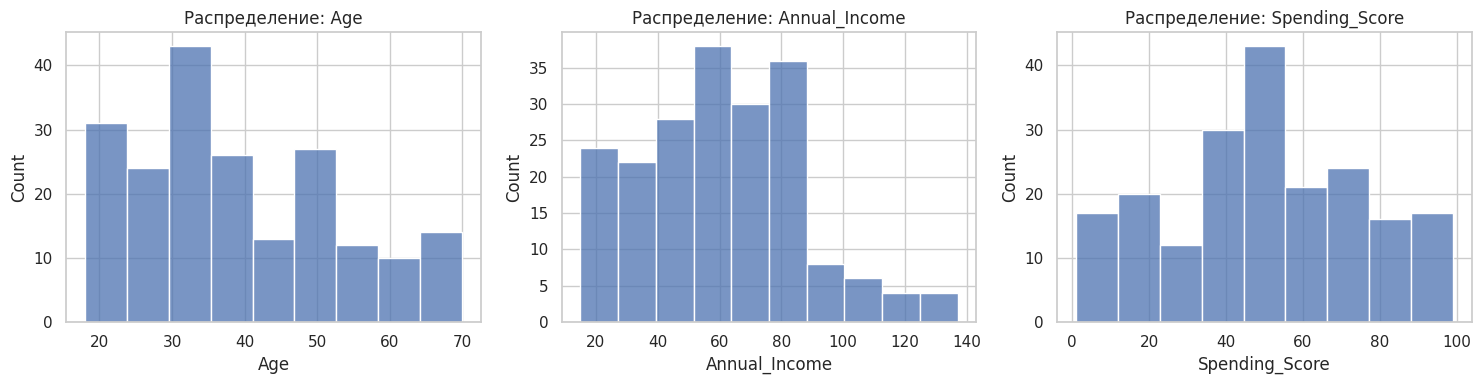

In [43]:
print("\nГистограммы признаков")
num_cols = ["Age", "Annual_Income", "Spending_Score"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(dt[col], kde=False, ax=ax)
    ax.set_title(f"Распределение: {col}")
plt.tight_layout()
plt.show()

Анализ гистограмм показал, что ни один из числовых признаков не имеет строго нормального распределения. Возраст (Age) имеет многовершинную структуру с пиком в районе 30-35 лет. Годовой доход (Annual_Income) смещен влево с ярко выраженным длинным "хвостом" в сторону высоких значений (до 137 тысяч), что указывает на наличие небольшого числа клиентов с аномально высоким доходом. Признак трат (Spending_Score) распределен относительно равномерно с незначительным пиком в области средних значений (40-50 баллов).

## Оценка информационной значимости признаков

Корреляционная матрица числовых признаков


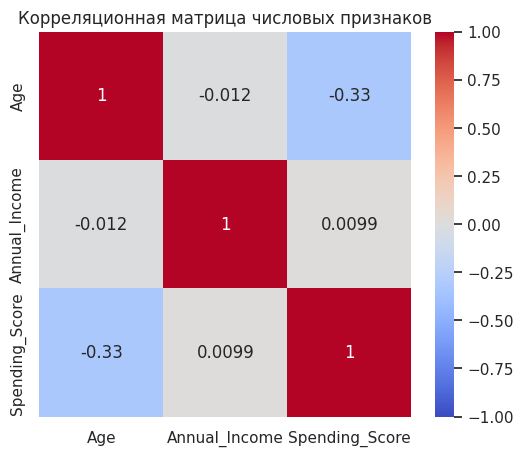

In [44]:
print("Корреляционная матрица числовых признаков")
plt.figure(figsize=(6, 5))
sns.heatmap(dt[num_cols].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Корреляционная матрица числовых признаков")
plt.show()

Корреляционная матрица показала отсутствие мультиколлинеарности между признаками, что делает их пригодными для совместного использования в алгоритмах кластеризации. Связь между годовым доходом и баллом трат практически отсутствует (r = 0.0099), что подтверждает их независимость. Наиболее заметная корреляция наблюдается между возрастом и баллом трат (r = -0.33): с увеличением возраста клиенты в среднем склонны тратить меньше. Возраст и доход также независимы (r = -0.012). Поскольку сильных корреляций не обнаружено, удаление или объединение признаков не требуется.

## Анализ выбросов

Диаграмма ящика с усами


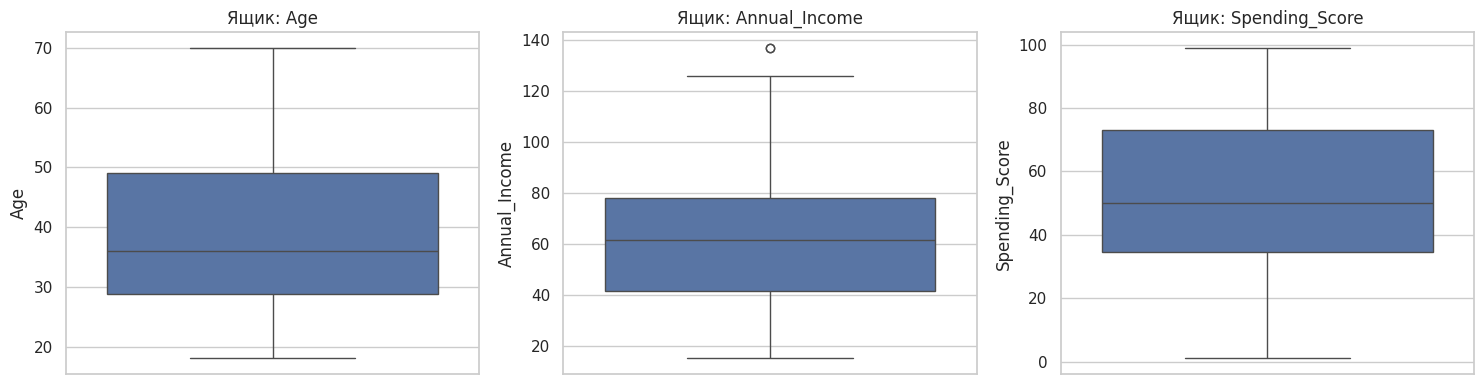

In [45]:
print("Диаграмма ящика с усами")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=dt[col], ax=ax)
    ax.set_title(f"Ящик: {col}")
plt.tight_layout()
plt.show()

На диаграмме ящика с усами видно, что в годовом доходе есть выбросы. Соответственно, одно из условий применения кластеризации нарушено - перед дальнейшей работой необходимо избавиться от выбросов.

In [46]:
print("Выбросы:")
outliers_idx = set()
for col in num_cols:
    q1, q3 = dt[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    mask = (dt[col] < lower) | (dt[col] > upper)
    outliers_count = mask.sum()

    idx = dt[col][mask].index
    outliers_idx.update(idx)

    print(f" {col}: {outliers_count}")

Выбросы:
 Age: 0
 Annual_Income: 2
 Spending_Score: 0


Итого в датасете имеются два выброса в Annual_Income (годовом доходе). Следовательно, перед стандартизацией будет необходимо избавиться от них.

# Предобработка данных

## Удаление выбросов

In [47]:
initial_shape = dt.shape[0]
outliers_idx = list(outliers_idx)
dt = dt.drop(index=outliers_idx).reset_index(drop=True)
print(f"Размер до удаления: {initial_shape}")
print(f"Размер после удаления: {dt.shape[0]}")

Размер до удаления: 200
Размер после удаления: 198


2 выброса, замеченные в Annual_Income, были успешно удалены. Размер датасета изменился с 200 строк до 198. Условие применения кластеризации - отсутствие выбросов, успешно выполнено.

## Приведение данных к стандартному виду

In [48]:
features = ["Annual_Income", "Spending_Score"]
X = dt[features].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Данные приведены к стандартному виду")

Данные приведены к стандартному виду


Перед применением алгоритмов кластеризации была выполнена стандартизация числовых признаков с помощью StandardScaler (Z-нормализации), приводящей данные к нулевому среднему и единичной дисперсии. Выбор данного метода обусловлен следующими причинами:

1.   Разные единицы измерения - признаки Annual_Income (тысячи долларов) и Spending_Score (баллы от 1 до 100) имеют совершенно разный масштаб.

2.   Наличие выбросов и асимметрии - гистограммы показали правостороннюю асимметрию в признаке Annual_Income. При использовании MinMaxScaler (приведения к диапазону [0, 1]) этот выброс сжал бы основную массу данных в узкий интервал, исказив структуру кластеров. StandardScaler же менее чувствителен к экстремальным значениям, так как опирается на среднее и стандартное отклонение.

## Матрица диаграмм рассеивания

Матрица рассеивания


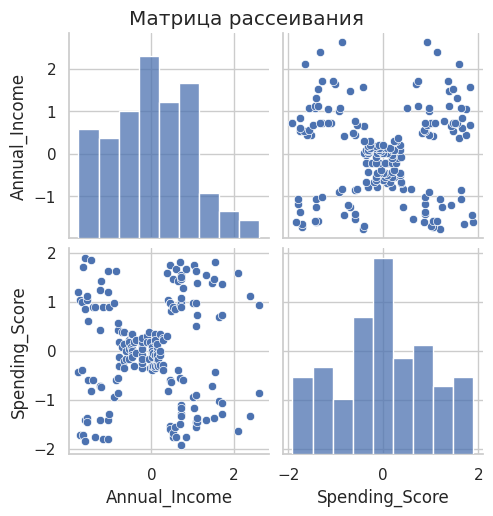

In [49]:
print("Матрица рассеивания")
sns.pairplot(pd.DataFrame(X_scaled, columns=features))
plt.suptitle("Матрица рассеивания", y=1.02)
plt.show()

На матрице диаграмм рассеивания видно наличие четко выраженной кластерной структуры. Точки образуют 5 хорошо изолированных сгустков: один крупный центральный и четыре вокруг него. Кластеры имеют примерно одинаковый размер и находятся на сопоставимом удалении друг от друга. Следовательно, условие осмысленности кластеризации выполняется.

## Аргументация выбора методов кластеризации на основе формы, размера и плотности кластеров

На основе визуального анализа матрицы диаграмм рассеивания были определены ключевые свойства кластерной структуры данных:

1.   Форма - кластеры имеют выпуклую, близкую к сферической форму. Отсутствуют кластеры сложной геометрии.

2.   Размер - группы сопоставимы по объему, за исключением одного более крупного центрального кластера.

3.   Плотность - точки внутри каждого сгустка распределены равномерно и достаточно плотно, без одиночных точек вдали от групп.

Рассмотрим каждый метод по отдельности.


1.   K-means (Метод K-средних) - итеративный алгоритм, который разбивает данные на k кластеров, минимизируя сумму квадратов расстояний от точек до центров своих кластеров (центоридов). Этот метод является быстрым, простым и хорошо работает на сферических кластерах одинакового размера.

2.   Иерархическая кластеризация (Agglomerative) - строит иерархию вложенных кластеров. Не требует заранее задавать k. Результат детерминирован и нагляден. Требует больших вычислительных ресурсов на больших выборках и чувствителен к выбросам.

3.   DBSCAN (Density-Based Spatial Clustering of Applications with Noise) - плотностной алгоритм, который группирует вместе точки, находящиеся в тесном соседстве, и помечает одиночные точки в разреженных областях как выбросы. Находит кластеры произвольной формы, не требует задавать число кластеров, устойчив к выбросам, но плохо работает, если плотность кластеров сильно различается.

4.   EM-алгоритм (Gaussian Mixture Model - GMM) - вероятностный алгоритм, который предполагает, что данные сгенерированы смесью нескольких многомерных нормальных распределений. В отличие от K-means, дает "мягкую" кластеризацию и может находить кластеры разного размера и вытянутой формы.

Исходя из этого, были выбраны два метода:

*   K-means (K-средних) - быстрый, простой и оптимален для сферических кластеров одинакового размера, как на наших диаграммах рассеивания.

*   EM-алгоритм (Gaussian Mixture - GMM) - выбран как вероятностное расширение K-means. Он также предполагает сферическую или слегка эллиптическую форму, но позволяет оценить вероятность принадлежности точки к кластеру и учесть разный размер / вытянутость групп.

Почему не иерархическая кластеризация и не DBSCAN?

*   Иерархическая кластеризация применима, но на выборке в 200 объектов K-means и EM работают быстрее.

*   DBSCAN отклонен, так как он предназначен для поиска кластеров произвольной формы и фильтрации выбросов. В наших данных отсутствует существенный шум, а структура глобально сферическая, поэтому DBSCAN избыточен.

# Подбор k: метод локтя и силуэтный анализ

Для определения оптимального значения k были использованы метод локтя и силуэтный анализ.

Диаграмма метода локтя и силуэтного анализа


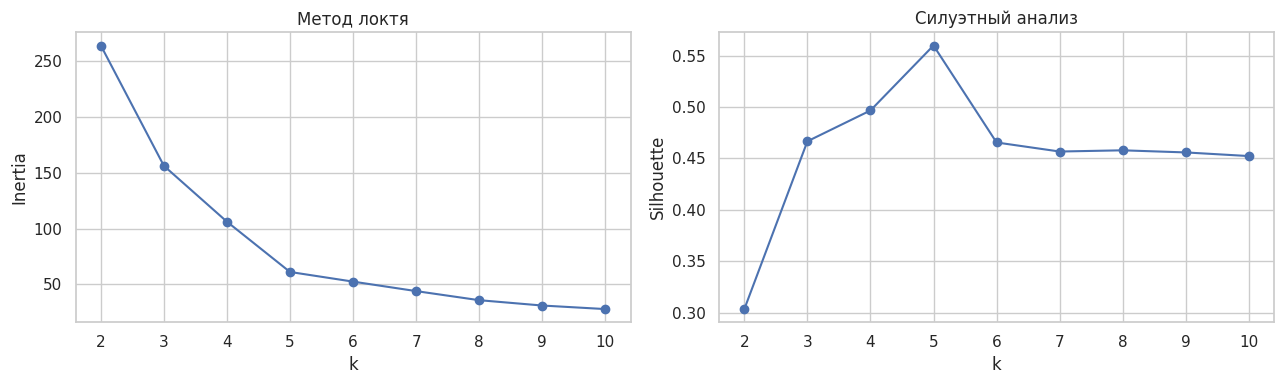

Оптимальное k: 5


In [50]:
inertia, sil_scores = [], []
k_range = range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, n_init=N_INIT, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_scaled)
    inertia.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

print("Диаграмма метода локтя и силуэтного анализа")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(list(k_range), inertia, "o-")
axes[0].set_title("Метод локтя")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")
axes[1].plot(list(k_range), sil_scores, "o-")
axes[1].set_title("Силуэтный анализ")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()

best_k = list(k_range)[int(np.argmax(sil_scores))]
print(f"Оптимальное k: {best_k}")

На графике метода локтя виден излом в точке k = 5. После этой точки график становится более пологим. График силуэтного анализа показывает глобальный максимум метрики Silhouette именно при k = 5 (значение примерно 0.56).

Таким образом, оба метода согласованно указывают на то, что оптимальным количеством кластеров для данного датасета является k = 5. Это значение и будет использовано в дальнейшем для алгоритмов K-means и EM.

# K-means

In [51]:
km = KMeans(n_clusters=best_k, n_init=N_INIT, random_state=RANDOM_STATE)
km_labels = km.fit_predict(X_scaled)
centers_km = km.cluster_centers_

print("Размеры кластеров K-means:", np.bincount(km_labels))

sil_km = silhouette_score(X_scaled, km_labels)
db_km = davies_bouldin_score(X_scaled, km_labels)
ch_km = calinski_harabasz_score(X_scaled, km_labels)

intra = []
for k in range(best_k):
    points = X_scaled[km_labels == k]
    center = centers_km[k:k+1]
    dist = cdist(points, center)
    intra.append(np.mean(dist))
inter = cdist(centers_km, centers_km)
inter_off = inter[~np.eye(best_k, dtype=bool)]

print(f"Среднее внутрикластерное расстояние: {np.mean(intra)}")
print(f"Среднее межкластерное расстояние: {np.mean(inter_off)}")

Размеры кластеров K-means: [22 35 38 80 23]
Среднее внутрикластерное расстояние: 0.5208258414970215
Среднее межкластерное расстояние: 2.3030996367399057


Полученное разбиение демонстрирует высокое качество кластерной структуры. Среднее внутрикластерное расстояние (примерно 0.52) более чем в 4 раза меньше среднего межкластерного расстояния (примерно 2.30), что свидетельствует о высокой компактности кластеров и их хорошей изолированности друг от друга.

Размеры кластеров распределены неравномерно: выделяется один крупный центральный кластер (80 клиентов) и четыре кластера меньшего размера (от 22 до 38 клиентов). Такое распределение является логичным для задачи сегментации рынка, где основная масса потребителей придерживается средних значений, а "крайние" поведенческие группы представлены меньшим числом клиентов.

Найденная структура не содержит аномально маленьких кластеров, что подтверждает устойчивость результата.

# EM-алгоритм (Gaussian Mixture)

In [52]:
gmm = GaussianMixture(n_components=best_k, covariance_type='full',
                      n_init=N_INIT, random_state=RANDOM_STATE)
gmm_labels = gmm.fit_predict(X_scaled)
gmm_means = gmm.means_

print("Размеры кластеров EM:", np.bincount(gmm_labels))

sil_gmm = silhouette_score(X_scaled, gmm_labels)
db_gmm = davies_bouldin_score(X_scaled, gmm_labels)
ch_gmm = calinski_harabasz_score(X_scaled, gmm_labels)

Размеры кластеров EM: [23 38 31 21 85]


Как и в случае с K-means размеры кластеров распределены неравномерно: выделяется один крупный центральный кластер (85 клиентов) и четыре кластера меньшего размера (от 21 до 38 клиентов). Найденная структура также не содержит аномально маленьких кластеров, что подтверждает устойчивость результата.

# Сравнительная таблица метрик качества и внешние метрики

## Сравнительная таблица метрик качества

In [53]:
metrics_table = pd.DataFrame({
    "Метрика": ["Silhouette", "Davies-Bouldin", "Calinski-Harabasz",
                "Число кластеров"],
    "K-means": [sil_km, db_km, ch_km, best_k],
    "EM (GMM)": [sil_gmm, db_gmm, ch_gmm, best_k]
})
print(metrics_table)

             Метрика     K-means    EM (GMM)
0         Silhouette    0.559920    0.558374
1     Davies-Bouldin    0.566211    0.572610
2  Calinski-Harabasz  264.535143  258.186380
3    Число кластеров    5.000000    5.000000


Сравнительная таблица показывает схожесть метрик K-means и EM (GMM), что говорит о высокой стабильности найденной кластерной структуры. Разберём отдельно каждую метрику:

*   Silhouette (примерно 0.56) - говорит об умеренно хорошей структуре:  точки в среднем заметно ближе к своему кластеру, чем к соседним.

*   Davies-Bouldin (примерно 0.57) - метрика измеряет среднее отношение внутрикластерного разброса к расстоянию между центрами (чем меньше - тем лучше, минимум = 0). Значение 0.57 означает, что кластеры достаточно компактны относительно расстояния между ними. У K-means показатель чуть ниже (0.566 против 0.573), то есть его кластеры немного плотнее.

*   Calinski-Harabasz (264.5 / 258.1) - метрика равна отношению межкластерной дисперсии к внутрикластерной (чем больше - тем лучше). Значения в сотнях указывают на то, что разброс между кластерами во много раз превышает разброс внутри них, то есть группы хорошо определены. Небольшое преимущество K-means объясняется тем, что этот алгоритм напрямую минимизирует внутрикластерную дисперсию, тогда как EM оптимизирует правдоподобие - это ожидаемое поведение.

*   Число кластеров (5) - оба метода сошлись на оптимальном k = 5, найденном ранее методом локтя и силуэта.

Близость всех трёх внутренних метрик свидетельствует о том, что K-means и EM-алгоритм нашли одну и ту же объективную структуру данных, просто разными математическими путями.

## Внешние метрики

In [54]:
rand = rand_score(km_labels, gmm_labels)
adjusted_rand = adjusted_rand_score(km_labels, gmm_labels)
print(f"Rand index = {rand}")
print(f"Adjusted Rand = {adjusted_rand}")

Rand index = 0.9718504845408399
Adjusted Rand = 0.9268698666563032


Внешние метрики были использованы для оценки степени согласия между разбиениями, полученными двумя алгоритмами:

*   Rand Index = 0.9718504845408399 - значение близко к 1, что означает: примерно в 97.2% случаев пары клиентов, отнесённые к одному кластеру одним методом, так же сгруппированы и другим. Лишь 2.8% пар получили разные оценки.

*   Adjusted Rand Index = 0.9268698666563032 - является более строгой метрикой, значение примерно 0.927 интерпретируется как очень высокое согласие между разбиениями.

Следовательно, высокие значения Rand Index и Adjusted Rand Index подтверждают, что K-means и EM-алгоритм (GMM) нашли практически идентичную кластерную структуру. Небольшие расхождения (около 7% по Adjusted Rand Index) легко объяснить "пограничными" клиентами, которые находятся примерно на равном удалении от двух центров: K-means жёстко относит их к одному кластеру по минимальному расстоянию, а EM распределяет вероятностно с учётом нормальной формы. Данные результаты доказывают устойчивость найденного разбиения - результат не зависит от выбранного алгоритма, что является признаком объективно существующей структуры в данных.

# Исследование влияния параметров EM-алгоритма на качество кластеризации

Для выбора оптимальной конфигурации EM-модели было проведено исследование четырёх типов ковариации.

In [55]:
results = []
for cov in ['full', 'tied', 'diag', 'spherical']:
    gmm_temp = GaussianMixture(n_components=best_k, covariance_type=cov,
                               n_init=N_INIT, random_state=RANDOM_STATE)
    gmm_temp.fit(X_scaled)
    lbl = gmm_temp.predict(X_scaled)
    s = silhouette_score(X_scaled, lbl)
    results.append((cov, s, gmm_temp.aic(X_scaled), gmm_temp.bic(X_scaled)))

res_dt = pd.DataFrame(results, columns=["covariance_type", "silhouette",
                                        "AIC", "BIC"])
print(res_dt.to_string(index=False))

covariance_type  silhouette        AIC         BIC
           full    0.558374 949.478998 1044.838742
           tied    0.558038 978.072434 1033.972974
           diag    0.559499 949.247048 1028.165456
      spherical    0.560310 964.488595 1026.965668


Результаты показали следующее:

*   Silhouette (Качество разделения) - все типы ковариации дают практически одинаковый результат - от 0.558 (tied) до 0.560 (spherical). Разница в третьем знаке после запятой означает, что форма кластеров в данных близка к сферической, и усложнение модели (переход к full) не даёт прироста качества разделения.

*   Минимальный AIC достигается у моделей diag (949.2) и full (949.5) - они лучше всего описывают данные с точки зрения правдоподобия.

*   Минимальный BIC - у spherical (1027.0) и diag (1028.2). Поскольку BIC сильнее штрафует за количество параметров, это говорит о том, что простая модель объясняет данные почти так же хорошо, как и сложная, но с меньшим риском переобучения.

Тип ковариации не является критическим параметром для данного датасета - все конфигурации находят одну и ту же структуру из 5 кластеров. Для основного анализа выбран тип full, так как он показал наилучший AIC (949.5) и позволяет модели учитывать возможную лёгкую вытянутость кластеров (в частности, центрального). При этом простота и устойчивость diag / spherical (лучший BIC) подтверждает, что кластеры близки к сферическим, что согласуется с исходным визуальным анализом.

# Визуализация результатов

## Диаграммы рассеивания с выделенными кластерами

Объяснённая дисперсия PCA: [0.50503987 0.49496013]


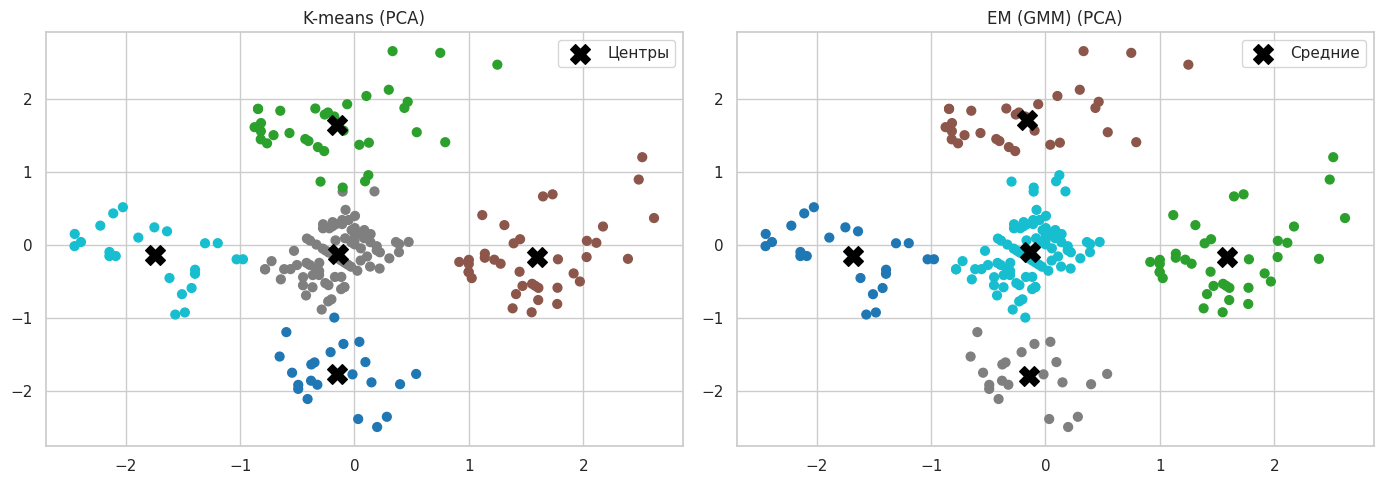

In [56]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
print("Объяснённая дисперсия PCA:", pca.explained_variance_ratio_)

centers_km_pca = pca.transform(centers_km)
centers_gmm_pca = pca.transform(gmm_means)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=km_labels,
    cmap="tab10",
    s=40
)
axes[0].scatter(
    centers_km_pca[:, 0],
    centers_km_pca[:, 1],
    marker="X",
    s=200,
    c="black",
    label="Центры"
)
axes[0].set_title("K-means (PCA)")
axes[0].legend()

axes[1].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=gmm_labels,
    cmap="tab10",
    s=40
)
axes[1].scatter(
    centers_gmm_pca[:, 0],
    centers_gmm_pca[:, 1],
    marker="X",
    s=200,
    c="black",
    label="Средние"
)
axes[1].set_title("EM (GMM) (PCA)")
axes[1].legend()

plt.tight_layout()
plt.show()

Для наглядного отображения полученных разбиений в двумерном пространстве было применено снижение размерности методом главных компонент (PCA). Две главные компоненты объясняют суммарно 99.99% дисперсии (50.50% и 49.50%), что означает: при переходе к двумерному пространству практически не произошло потери информации, и графики отражают реальную структуру данных без существенных искажений.

Содержательная интерпретация выделенных групп:

1.   "Экономные" (низкий доход / низкие траты): доход примерно 26 тысяч, траты примерно 21 балл. Клиенты с ограниченным бюджетом, которые предпочитают не совершать импульсивных покупок.

2.   "Импульсивные покупатели" (низкий доход / высокие траты): доход примерно 25 тысяч, траты примерно 79 баллов. Клиенты, готовые тратить много даже при скромном доходе.

3.   "Финансово грамотные" (высокий доход / низкие траты): доход примерно 86 тысяч, траты примерно 17 баллов. Обеспеченные, но осторожные клиенты. Возможно, они делают покупки в других магазинах или не видят ценности в предлагаемых товарах.

4.   "Богачи" (высокий доход / высокие траты): доход примерно 85 тысяч, траты примерно 82 балла. Самые ценные покупатели, готовые тратить большие суммы.

5.   "Средний класс" (средний доход / средние траты): доход примерно 55 тысяч, траты примерно 50 баллов. Самая многочисленная группа (около 80 человек). Стабильные покупатели со средним чеком.

Сравнение результатов, полученные двумя разными методами:

1.   Схожесть разбиений - как и предполагалось по метрикам (Adjusted Rand Index примерно 0.927), визуализация наглядно подтверждает, что K-means и EM-алгоритм нашли практически идентичную структуру. Легко заметить 5 четко изолированных сгустков на обоих графиках.

2.   Расположение кластеров - точки образуют компактные группы, соответствующие сегментам клиентов: центральный кластер - самая многочисленная группа клиентов со средними доходом и тратами и четыре кластера вокруг - "крайние" поведенческие сегменты.

3.   Положение центров - чёрные крестики расположены в геометрических центрах своих сгустков и практически совпадают по координатам на обоих графиках, что дополнительно подтверждает согласованность методов.

4.   Различия методов - единственное визуальное отличие - цветовая маркировка кластеров. Например, верхний левый кластер у K-means зелёный, а у EM - коричневый. Это не является расхождением в структуре, а лишь следствием того, что алгоритмы присваивают кластерам номера в разном порядке. Некоторые "пограничные" точки между центральным и соседними кластерами могут переходить из группы в группу, что и объясняет Adjusted Rand Index < 1.

## Cравнение результатов разных методов

In [57]:
print("K-means")
centers_orig_km = scaler.inverse_transform(centers_km)
centers_dt_km = pd.DataFrame(centers_orig_km, columns=features)
centers_dt_km["Размер кластера"] = np.bincount(km_labels)
print("Центры K-means:")
print(centers_dt_km)

print("\nEM-алгоритм (Gaussian Mixture)")
centers_orig_gmm = scaler.inverse_transform(gmm_means)
centers_dt_gmm = pd.DataFrame(centers_orig_gmm, columns=features)
centers_dt_gmm["Размер кластера"] = np.bincount(gmm_labels)
print("Средние значения EM (GMM):")
print(centers_dt_gmm)

K-means
Центры K-means:
   Annual_Income  Spending_Score  Размер кластера
0      25.727273       79.363636               22
1      86.342857       17.571429               35
2      85.210526       82.105263               38
3      55.087500       49.712500               80
4      26.304348       20.913043               23

EM-алгоритм (Gaussian Mixture)
Средние значения EM (GMM):
   Annual_Income  Spending_Score  Размер кластера
0      27.122565       22.289583               23
1      85.055093       81.992472               38
2      87.385236       16.054853               31
3      25.162662       80.158274               21
4      55.736853       49.409303               85


Сопоставление координат центров кластеров, полученных двумя методами, показало их практически полное совпадение. Различия между методами носят исключительно технический характер (нумерация кластеров и распределение пограничных точек). Содержательная интерпретация сегментов полностью совпадает, что доказывает устойчивость и объективность найденной кластерной структуры. Для бизнес-задач сегментации оба метода равнозначны.

# Заключение

В ходе выполнения лабораторной работы была решена задача кластеризации клиентской базы на основе датасета Mall Customers (200 записей). Целью работы было изучение алгоритмов кластеризации, оценка качества разбиения и интерпретация результатов.

## Сравнительный анализ эффективности методов

Для оценки эффективности методы сравнивались по трем группам критериев: качество разбиения, вычислительная сложность и интерпретируемость.

*   Качество разбиения и согласованность - оба метода показали практически идентичные результаты. Внутренние метрики (Silhouette примерно 0.56, Davies-Bouldin примерно 0.57) оказались незначительно лучше у K-means. Однако значение Adjusted Rand Index (0.927) подтверждает, что оба алгоритма выделили одну и ту же структуру.

*   Скорость и вычислительная сложность - K-means работает быстрее, так как оперирует только расстояниями до центроидов. EM-алгоритм (GMM) требует больше вычислений из-за необходимости расчета матриц ковариации и вероятностей, что на больших данных может стать критичным фактором.

*   Стабильность - K-means более устойчив к начальной инициализации. EM-алгоритм без параметра n_init склонен попадать в локальные оптимумы.

*   Интерпретируемость - оба метода дают чёткие координаты центров кластеров, что позволяет легко дать бизнес-интерпретацию сегментов. Однако EM-алгоритм предоставляет дополнительное преимущество - вероятностную оценку принадлежности клиента к кластеру. Это полезно для анализа "пограничных" клиентов.

Для быстрой и надежной сегментации на данном типе данных оптимален K-means. Если же бизнес-задача требует оценки уверенности модели в отнесении клиента к сегменту, предпочтительнее EM-алгоритм. Методы DBSCAN и иерархической кластеризации признаны менее пригодными для данной задачи из-за отсутствия шума (DBSCAN) и избыточной вычислительной сложности (иерархический метод).

## Интерпретация выделенных кластеров

Оба метода выделили пять идентичных по смыслу бизнес-сегментов:

1.   "Экономные" (низкий доход / низкие траты) - клиенты с ограниченным бюджетом.
2.   "Импульсивные покупатели" (низкий доход / высокие траты) - активные покупатели, склонные к импульсивным покупкам.
3.   "Финансово грамотные" (высокий доход / низкие траты) - обеспеченные, но осторожные клиенты.
4.   "Богачи" (высокий доход / высокие траты) - наиболее ценная группа для бизнеса.
5.   "Средний класс" (средний доход / средние траты) - самая многочисленная группа.

## Выводы о применимости методов к данному типу данных

K-means и EM-алгоритм показали себя как эффективные инструменты для данного типа данных (низкая размерность, сферическая форма кластеров, отсутствие существенных выбросов).

K-means является более быстрым и простым в вычислительном плане. Он напрямую минимизирует внутрикластерную дисперсию, что делает его предпочтительным для быстрой сегментации.

EM-алгоритм (GMM) обеспечивает более гибкую вероятностную интерпретацию (позволяет оценить уверенность отнесения клиента к группе) и может учитывать форму кластеров.

DBSCAN и иерархическая кластеризация были признаны менее подходящими: DBSCAN избыточен из-за отсутствия шума в данных, а иерархический метод требует больше ресурсов.

# Список источников

1.   Scikit-learn: Machine Learning in Python / Pedregosa F., Varoquaux G., Gramfort A., et al. - Journal of Machine Learning Research, 2011. - Vol. 12. - P. 2825-2830.

2.   Mall Customer Segmentation Data / Kaggle. - URL: https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python (дата обращения: 22.10.2026).

3.   Воронцов К.В. Алгоритмы кластеризации и их применение: учебно-методическое пособие. - М.: МГУ, 2018. (Теория K-means, EM-алгоритма и метрик качества).

# Приложение. Полный листинг программного кода

===== 1. Описание датасета =====
===== 1.1. Описание датасета =====
Название датасета: Kaggle - Mall Customers
Исходный размер: (200, 5)
   CustomerID  Gender  Age  Annual_Income  Spending_Score
0           1    Male   19             15              39
1           2    Male   21             15              81
2           3  Female   20             16               6
3           4  Female   23             16              77
4           5  Female   31             17              40

Информация о датасете
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   CustomerID      200 non-null    int64 
 1   Gender          200 non-null    object
 2   Age             200 non-null    int64 
 3   Annual_Income   200 non-null    int64 
 4   Spending_Score  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Количество пропусков
Customer

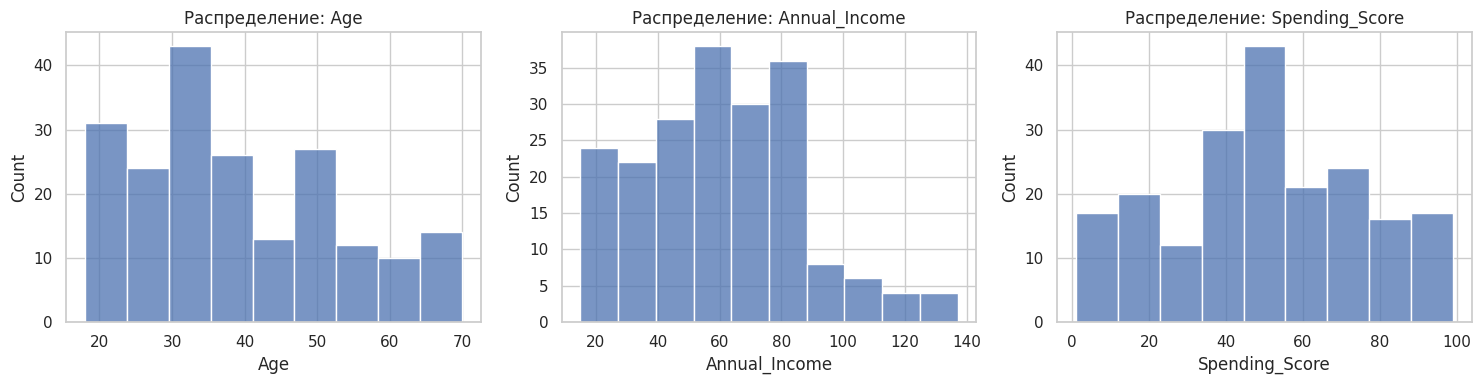


===== 1.3. Оценка информационной значимости признаков =====
Корреляционная матрица числовых признаков


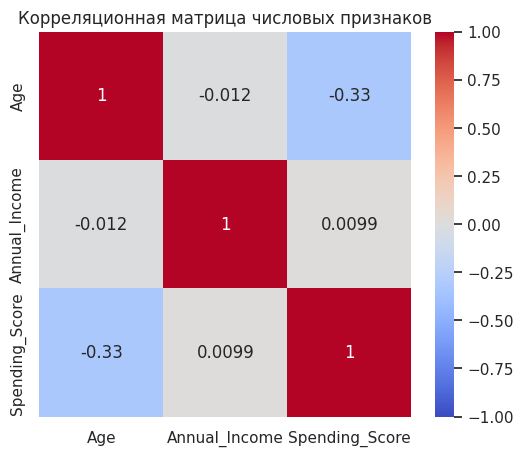


===== 1.4. Анализ выбросов =====
Диаграмма ящика с усами


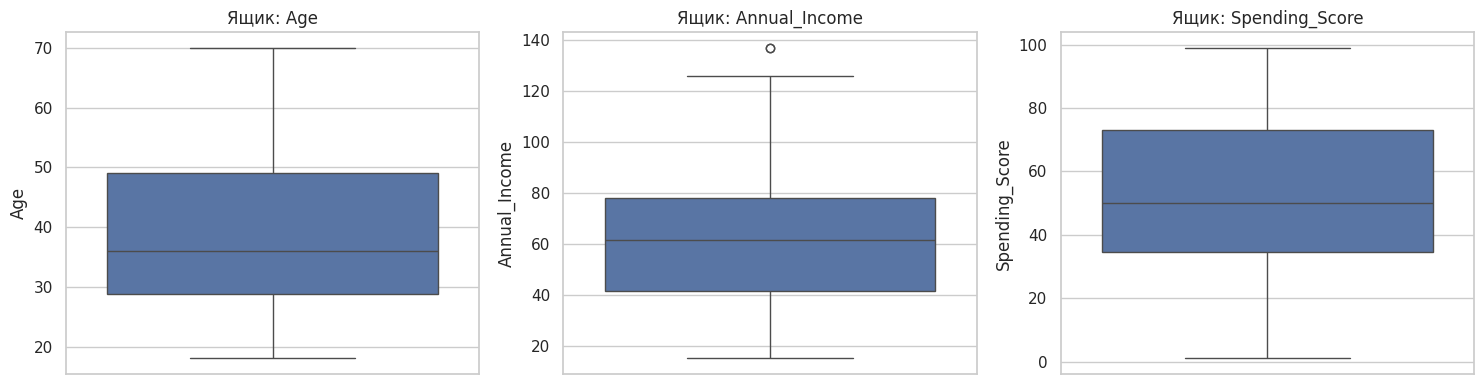

Выбросы:
 Age: 0
 Annual_Income: 2
 Spending_Score: 0

===== 2. Предобработка данных =====
===== 2.1. Удаление выбросов =====
Размер до удаления: 200
Размер после удаления: 198

===== 2.2. Приведение данных к стандартному виду =====
Данные приведены к стандартному виду

===== 2.3. Матрица диаграмм рассеивания =====
Матрица рассеивания


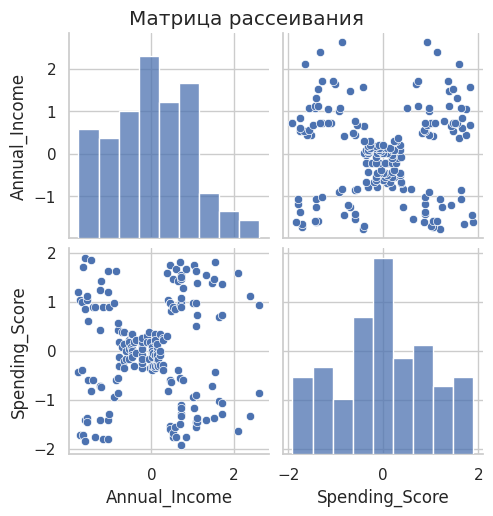


===== 3. Подбор k: метод локтя и силуэтный анализ =====
Диаграмма метода локтя и силуэтного анализа


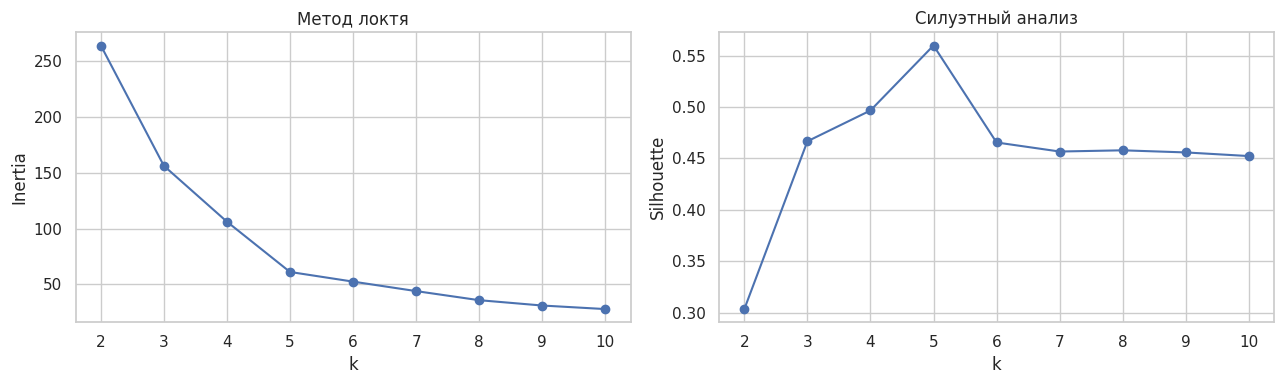

Оптимальное k: 5

===== 4. K-means =====
Размеры кластеров K-means: [22 35 38 80 23]
Среднее внутрикластерное расстояние: 0.5208258414970215
Среднее межкластерное расстояние: 2.3030996367399057

===== 5. EM-алгоритм (Gaussian Mixture) =====
Размеры кластеров EM: [23 38 31 21 85]

===== 6. Сравнительная таблица метрик и внешние метрики =====
===== 6.1. Сравнительная таблица метрик качества =====
             Метрика     K-means    EM (GMM)
0         Silhouette    0.559920    0.558374
1     Davies-Bouldin    0.566211    0.572610
2  Calinski-Harabasz  264.535143  258.186380
3    Число кластеров    5.000000    5.000000

===== 6.2. Внешние метрики =====
Rand index = 0.9718504845408399
Adjusted Rand = 0.9268698666563032

===== 7. Влияние параметров EM (тип ковариации) =====
covariance_type  silhouette        AIC         BIC
           full    0.558374 949.478998 1044.838742
           tied    0.558038 978.072434 1033.972974
           diag    0.559499 949.247048 1028.165456
      spherical  

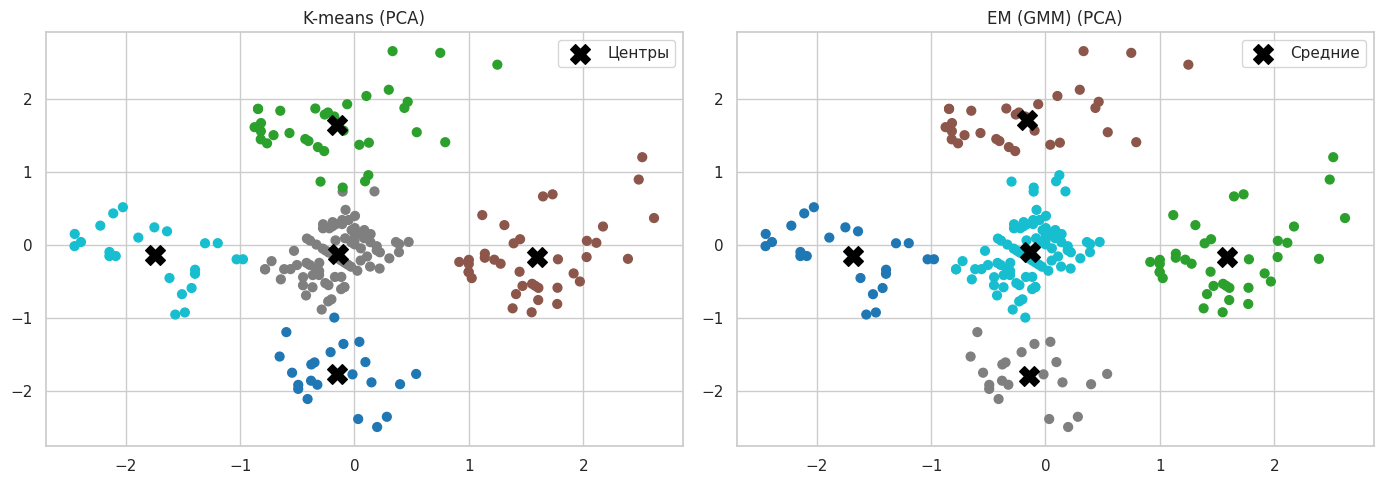


===== 9. Интерпретация центров K-means и EM =====
K-means
Центры K-means:
   Annual_Income  Spending_Score  Размер кластера
0      25.727273       79.363636               22
1      86.342857       17.571429               35
2      85.210526       82.105263               38
3      55.087500       49.712500               80
4      26.304348       20.913043               23

EM-алгоритм (Gaussian Mixture)
Средние значения EM (GMM):
   Annual_Income  Spending_Score  Размер кластера
0      27.122565       22.289583               23
1      85.055093       81.992472               38
2      87.385236       16.054853               31
3      25.162662       80.158274               21
4      55.736853       49.409303               85


In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    rand_score,
    adjusted_rand_score
)
from scipy.spatial.distance import cdist

RANDOM_STATE = 42
N_INIT = 10

sns.set_theme(style="whitegrid")
np.random.seed(RANDOM_STATE)

print("===== 1. Описание датасета =====")
print("===== 1.1. Описание датасета =====")

dt = pd.read_csv("Mall_Customers.csv")
dt = dt.rename(columns={
    "Annual Income (k$)": "Annual_Income",
    "Spending Score (1-100)": "Spending_Score",
    "Genre": "Gender"
})

print("Название датасета: Kaggle - Mall Customers")
print(f"Исходный размер: {dt.shape}")
print(dt.head())

print("\nИнформация о датасете")
dt.info()

print("\nКоличество пропусков")
print(dt.isna().sum())

print("\n===== 1.2. Визуализация распределения признаков =====")
print(dt.describe())
print("\nРаспределение мужчин и женщин")
print(dt["Gender"].value_counts())

print("\nГистограммы признаков")
num_cols = ["Age", "Annual_Income", "Spending_Score"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(dt[col], kde=False, ax=ax)
    ax.set_title(f"Распределение: {col}")
plt.tight_layout()
plt.show()

print("\n===== 1.3. Оценка информационной значимости признаков =====")
print("Корреляционная матрица числовых признаков")
plt.figure(figsize=(6, 5))
sns.heatmap(dt[num_cols].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Корреляционная матрица числовых признаков")
plt.show()

print("\n===== 1.4. Анализ выбросов =====")
print("Диаграмма ящика с усами")
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=dt[col], ax=ax)
    ax.set_title(f"Ящик: {col}")
plt.tight_layout()
plt.show()

print("Выбросы:")
outliers_idx = set()
for col in num_cols:
    q1, q3 = dt[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    mask = (dt[col] < lower) | (dt[col] > upper)
    outliers_count = mask.sum()

    idx = dt[col][mask].index
    outliers_idx.update(idx)

    print(f" {col}: {outliers_count}")


print("\n===== 2. Предобработка данных =====")
print("===== 2.1. Удаление выбросов =====")
initial_shape = dt.shape[0]
outliers_idx = list(outliers_idx)
dt = dt.drop(index=outliers_idx).reset_index(drop=True)
print(f"Размер до удаления: {initial_shape}")
print(f"Размер после удаления: {dt.shape[0]}")

print("\n===== 2.2. Приведение данных к стандартному виду =====")
features = ["Annual_Income", "Spending_Score"]
X = dt[features].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Данные приведены к стандартному виду")

print("\n===== 2.3. Матрица диаграмм рассеивания =====")
print("Матрица рассеивания")
sns.pairplot(pd.DataFrame(X_scaled, columns=features))
plt.suptitle("Матрица рассеивания", y=1.02)
plt.show()


print("\n===== 3. Подбор k: метод локтя и силуэтный анализ =====")
inertia, sil_scores = [], []
k_range = range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, n_init=N_INIT, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_scaled)
    inertia.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

print("Диаграмма метода локтя и силуэтного анализа")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(list(k_range), inertia, "o-")
axes[0].set_title("Метод локтя")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")
axes[1].plot(list(k_range), sil_scores, "o-")
axes[1].set_title("Силуэтный анализ")
axes[1].set_xlabel("k")
axes[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()

best_k = list(k_range)[int(np.argmax(sil_scores))]
print(f"Оптимальное k: {best_k}")


print("\n===== 4. K-means =====")
km = KMeans(n_clusters=best_k, n_init=N_INIT, random_state=RANDOM_STATE)
km_labels = km.fit_predict(X_scaled)
centers_km = km.cluster_centers_

print("Размеры кластеров K-means:", np.bincount(km_labels))

sil_km = silhouette_score(X_scaled, km_labels)
db_km = davies_bouldin_score(X_scaled, km_labels)
ch_km = calinski_harabasz_score(X_scaled, km_labels)

intra = []
for k in range(best_k):
    points = X_scaled[km_labels == k]
    center = centers_km[k:k+1]
    dist = cdist(points, center)
    intra.append(np.mean(dist))
inter = cdist(centers_km, centers_km)
inter_off = inter[~np.eye(best_k, dtype=bool)]

print(f"Среднее внутрикластерное расстояние: {np.mean(intra)}")
print(f"Среднее межкластерное расстояние: {np.mean(inter_off)}")


print("\n===== 5. EM-алгоритм (Gaussian Mixture) =====")
gmm = GaussianMixture(n_components=best_k, covariance_type='full',
                      n_init=N_INIT, random_state=RANDOM_STATE)
gmm_labels = gmm.fit_predict(X_scaled)
gmm_means = gmm.means_

print("Размеры кластеров EM:", np.bincount(gmm_labels))

sil_gmm = silhouette_score(X_scaled, gmm_labels)
db_gmm = davies_bouldin_score(X_scaled, gmm_labels)
ch_gmm = calinski_harabasz_score(X_scaled, gmm_labels)


print("\n===== 6. Сравнительная таблица метрик и внешние метрики =====")
print("===== 6.1. Сравнительная таблица метрик качества =====")
metrics_table = pd.DataFrame({
    "Метрика": ["Silhouette", "Davies-Bouldin", "Calinski-Harabasz",
                "Число кластеров"],
    "K-means": [sil_km, db_km, ch_km, best_k],
    "EM (GMM)": [sil_gmm, db_gmm, ch_gmm, best_k]
})
print(metrics_table)

print("\n===== 6.2. Внешние метрики =====")
rand = rand_score(km_labels, gmm_labels)
adjusted_rand = adjusted_rand_score(km_labels, gmm_labels)
print(f"Rand index = {rand}")
print(f"Adjusted Rand = {adjusted_rand}")


print("\n===== 7. Влияние параметров EM (тип ковариации) =====")
results = []
for cov in ['full', 'tied', 'diag', 'spherical']:
    gmm_temp = GaussianMixture(n_components=best_k, covariance_type=cov,
                               n_init=N_INIT, random_state=RANDOM_STATE)
    gmm_temp.fit(X_scaled)
    lbl = gmm_temp.predict(X_scaled)
    s = silhouette_score(X_scaled, lbl)
    results.append((cov, s, gmm_temp.aic(X_scaled), gmm_temp.bic(X_scaled)))

res_dt = pd.DataFrame(results, columns=["covariance_type", "silhouette",
                                        "AIC", "BIC"])
print(res_dt.to_string(index=False))


print("\n===== 8. Визуализация кластеров через PCA =====")
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
print("Объяснённая дисперсия PCA:", pca.explained_variance_ratio_)

centers_km_pca = pca.transform(centers_km)
centers_gmm_pca = pca.transform(gmm_means)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=km_labels,
    cmap="tab10",
    s=40
)
axes[0].scatter(
    centers_km_pca[:, 0],
    centers_km_pca[:, 1],
    marker="X",
    s=200,
    c="black",
    label="Центры"
)
axes[0].set_title("K-means (PCA)")
axes[0].legend()

axes[1].scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=gmm_labels,
    cmap="tab10",
    s=40
)
axes[1].scatter(
    centers_gmm_pca[:, 0],
    centers_gmm_pca[:, 1],
    marker="X",
    s=200,
    c="black",
    label="Средние"
)
axes[1].set_title("EM (GMM) (PCA)")
axes[1].legend()

plt.tight_layout()
plt.show()


print("\n===== 9. Интерпретация центров K-means и EM =====")
print("K-means")
centers_orig_km = scaler.inverse_transform(centers_km)
centers_dt_km = pd.DataFrame(centers_orig_km, columns=features)
centers_dt_km["Размер кластера"] = np.bincount(km_labels)
print("Центры K-means:")
print(centers_dt_km)

print("\nEM-алгоритм (Gaussian Mixture)")
centers_orig_gmm = scaler.inverse_transform(gmm_means)
centers_dt_gmm = pd.DataFrame(centers_orig_gmm, columns=features)
centers_dt_gmm["Размер кластера"] = np.bincount(gmm_labels)
print("Средние значения EM (GMM):")
print(centers_dt_gmm)